In [ ]:
# ==============================
# DLG + iDLG + GradInversion
# REAL FL CLIENT UPDATE VERSION
# EMNIST Letters (26 classes)
# 4 Models:
# Baseline
# Masking Only
# Masking + ANF=0.1
# Masking + ANF=0.2
# ==============================

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import numpy as np
import random
import copy
import os
from google.colab import files

# -------------------------
# Seed
# -------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# -------------------------
# Device
# -------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# -------------------------
# Dataset
# -------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

dataset = torchvision.datasets.EMNIST(
    root="./data",
    split="letters",
    train=True,
    download=True,
    transform=transform
)

NUM_CLASSES = 26

# -------------------------
# Model
# -------------------------
class EMNIST_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64 * 7 * 7, 256)
        self.fc2 = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# -------------------------
# Load models
# -------------------------
def load_model(path):
    m = EMNIST_CNN().to(DEVICE)
    m.load_state_dict(torch.load(path, map_location=DEVICE))
    m.eval()
    return m

models = {
    "baseline": load_model("Baseline_emnist_letters.pth"),
    "fpman0": load_model("FPMAN_emnist_letters_0.pth"),
    "fpman1": load_model("FPMAN_emnist_letters_1.pth"),
    "fpman2": load_model("FPMAN_emnist_letters_2.pth")
}

# -------------------------
# One sample per class
# -------------------------
letter_samples = {}
for img, label in dataset:
    label = label - 1
    if label not in letter_samples:
        letter_samples[label] = img
    if len(letter_samples) == 26:
        break

# -------------------------
# FL CLIENT UPDATE (IMPORTANT FIX)
# -------------------------
def get_client_update(model, image, label):

    local = copy.deepcopy(model)
    local.train()

    opt = torch.optim.SGD(local.parameters(), lr=0.01)

    # local training (1 sample = worst-case FL client)
    for _ in range(5):
        opt.zero_grad()
        out = local(image)
        loss = F.cross_entropy(out, label)
        loss.backward()
        opt.step()

    # FL update (THIS is what server sees)
    delta = []
    for p0, p1 in zip(model.parameters(), local.parameters()):
        delta.append((p1.data - p0.data).clone().view(-1))

    return torch.cat(delta)

# -------------------------
# Gradient-based attacks (on FL update)
# -------------------------
def dlg_attack(model, update, shape, label, steps=300, lr=0.05):

    dummy = torch.randn(shape, device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([dummy], lr=lr)

    model_vec = update  # FL update

    for _ in range(steps):
        opt.zero_grad()

        loss = F.cross_entropy(model(dummy), label)

        grads = torch.autograd.grad(loss, model.parameters(), create_graph=True)

        grad_vec = torch.cat([g.view(-1) for g in grads])

        loss = ((grad_vec - model_vec) ** 2).sum()

        loss.backward()
        opt.step()

        dummy.data.clamp_(-1, 1)

    return dummy.detach()

# -------------------------
# iDLG
# -------------------------
def idlg_attack(model, update, shape, steps=300, lr=0.05):

    dummy = torch.randn(shape, device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([dummy], lr=lr)

    recovered_label = torch.tensor([0]).to(DEVICE)

    for _ in range(steps):
        opt.zero_grad()

        loss = F.cross_entropy(model(dummy), recovered_label)

        grads = torch.autograd.grad(loss, model.parameters(), create_graph=True)

        grad_vec = torch.cat([g.view(-1) for g in grads])

        loss = ((grad_vec - update) ** 2).sum()

        loss.backward()
        opt.step()

        dummy.data.clamp_(-1, 1)

    return dummy.detach()

# -------------------------
# GradInv
# -------------------------
def gradinv_attack(model, update, shape, label, steps=300, lr=0.05):

    dummy = torch.randn(shape, device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([dummy], lr=lr)

    for _ in range(steps):
        opt.zero_grad()

        loss = F.cross_entropy(model(dummy), label)

        grads = torch.autograd.grad(loss, model.parameters(), create_graph=True)

        grad_vec = torch.cat([g.view(-1) for g in grads])

        loss = ((grad_vec - update) ** 2).sum()

        loss.backward()
        opt.step()

        dummy.data.clamp_(-1, 1)

    return dummy.detach()

# -------------------------
# RUN ATTACKS ON REAL FL UPDATE
# -------------------------
results = {k: {"dlg": [], "idlg": [], "gi": []} for k in models}
original = []

for c in range(26):

    print("\nClass:", c)

    img = letter_samples[c].unsqueeze(0).to(DEVICE)
    label = torch.tensor([c]).to(DEVICE)

    original.append(img.cpu().numpy()[0][0])

    for name, model in models.items():

        print("Model:", name)

        # REAL FL UPDATE (IMPORTANT FIX)
        update = get_client_update(model, img, label)

        print(" DLG")
        r1 = dlg_attack(model, update, img.shape, label)
        results[name]["dlg"].append(r1.cpu().numpy()[0][0])

        print(" iDLG")
        r2 = idlg_attack(model, update, img.shape)
        results[name]["idlg"].append(r2.cpu().numpy()[0][0])

        print(" GradInv")
        r3 = gradinv_attack(model, update, img.shape, label)
        results[name]["gi"].append(r3.cpu().numpy()[0][0])

# -------------------------
# Done
# -------------------------
print("FINISHED REAL FL ATTACK EXPERIMENT")

Device: cpu

Class: 0
Model: baseline
 DLG
 iDLG
 GradInv
Model: fpman0
 DLG
 iDLG
 GradInv
Model: fpman1
 DLG
 iDLG
 GradInv
Model: fpman2
 DLG
 iDLG
 GradInv

Class: 1
Model: baseline
 DLG
 iDLG
 GradInv
Model: fpman0
 DLG
 iDLG
 GradInv
Model: fpman1
 DLG
 iDLG
 GradInv
Model: fpman2
 DLG
 iDLG
 GradInv

Class: 2
Model: baseline
 DLG
 iDLG
 GradInv
Model: fpman0
 DLG
 iDLG
 GradInv
Model: fpman1
 DLG
 iDLG
 GradInv
Model: fpman2
 DLG
 iDLG
 GradInv

Class: 3
Model: baseline
 DLG
 iDLG
 GradInv
Model: fpman0
 DLG
 iDLG
 GradInv
Model: fpman1
 DLG
 iDLG
 GradInv
Model: fpman2
 DLG
 iDLG
 GradInv

Class: 4
Model: baseline
 DLG
 iDLG
 GradInv
Model: fpman0
 DLG
 iDLG
 GradInv
Model: fpman1
 DLG
 iDLG
 GradInv
Model: fpman2
 DLG
 iDLG
 GradInv

Class: 5
Model: baseline
 DLG
 iDLG
 GradInv
Model: fpman0
 DLG
 iDLG
 GradInv
Model: fpman1
 DLG
 iDLG
 GradInv
Model: fpman2
 DLG
 iDLG
 GradInv

Class: 6
Model: baseline
 DLG
 iDLG
 GradInv
Model: fpman0
 DLG
 iDLG
 GradInv
Model: fpman1
 DLG
 

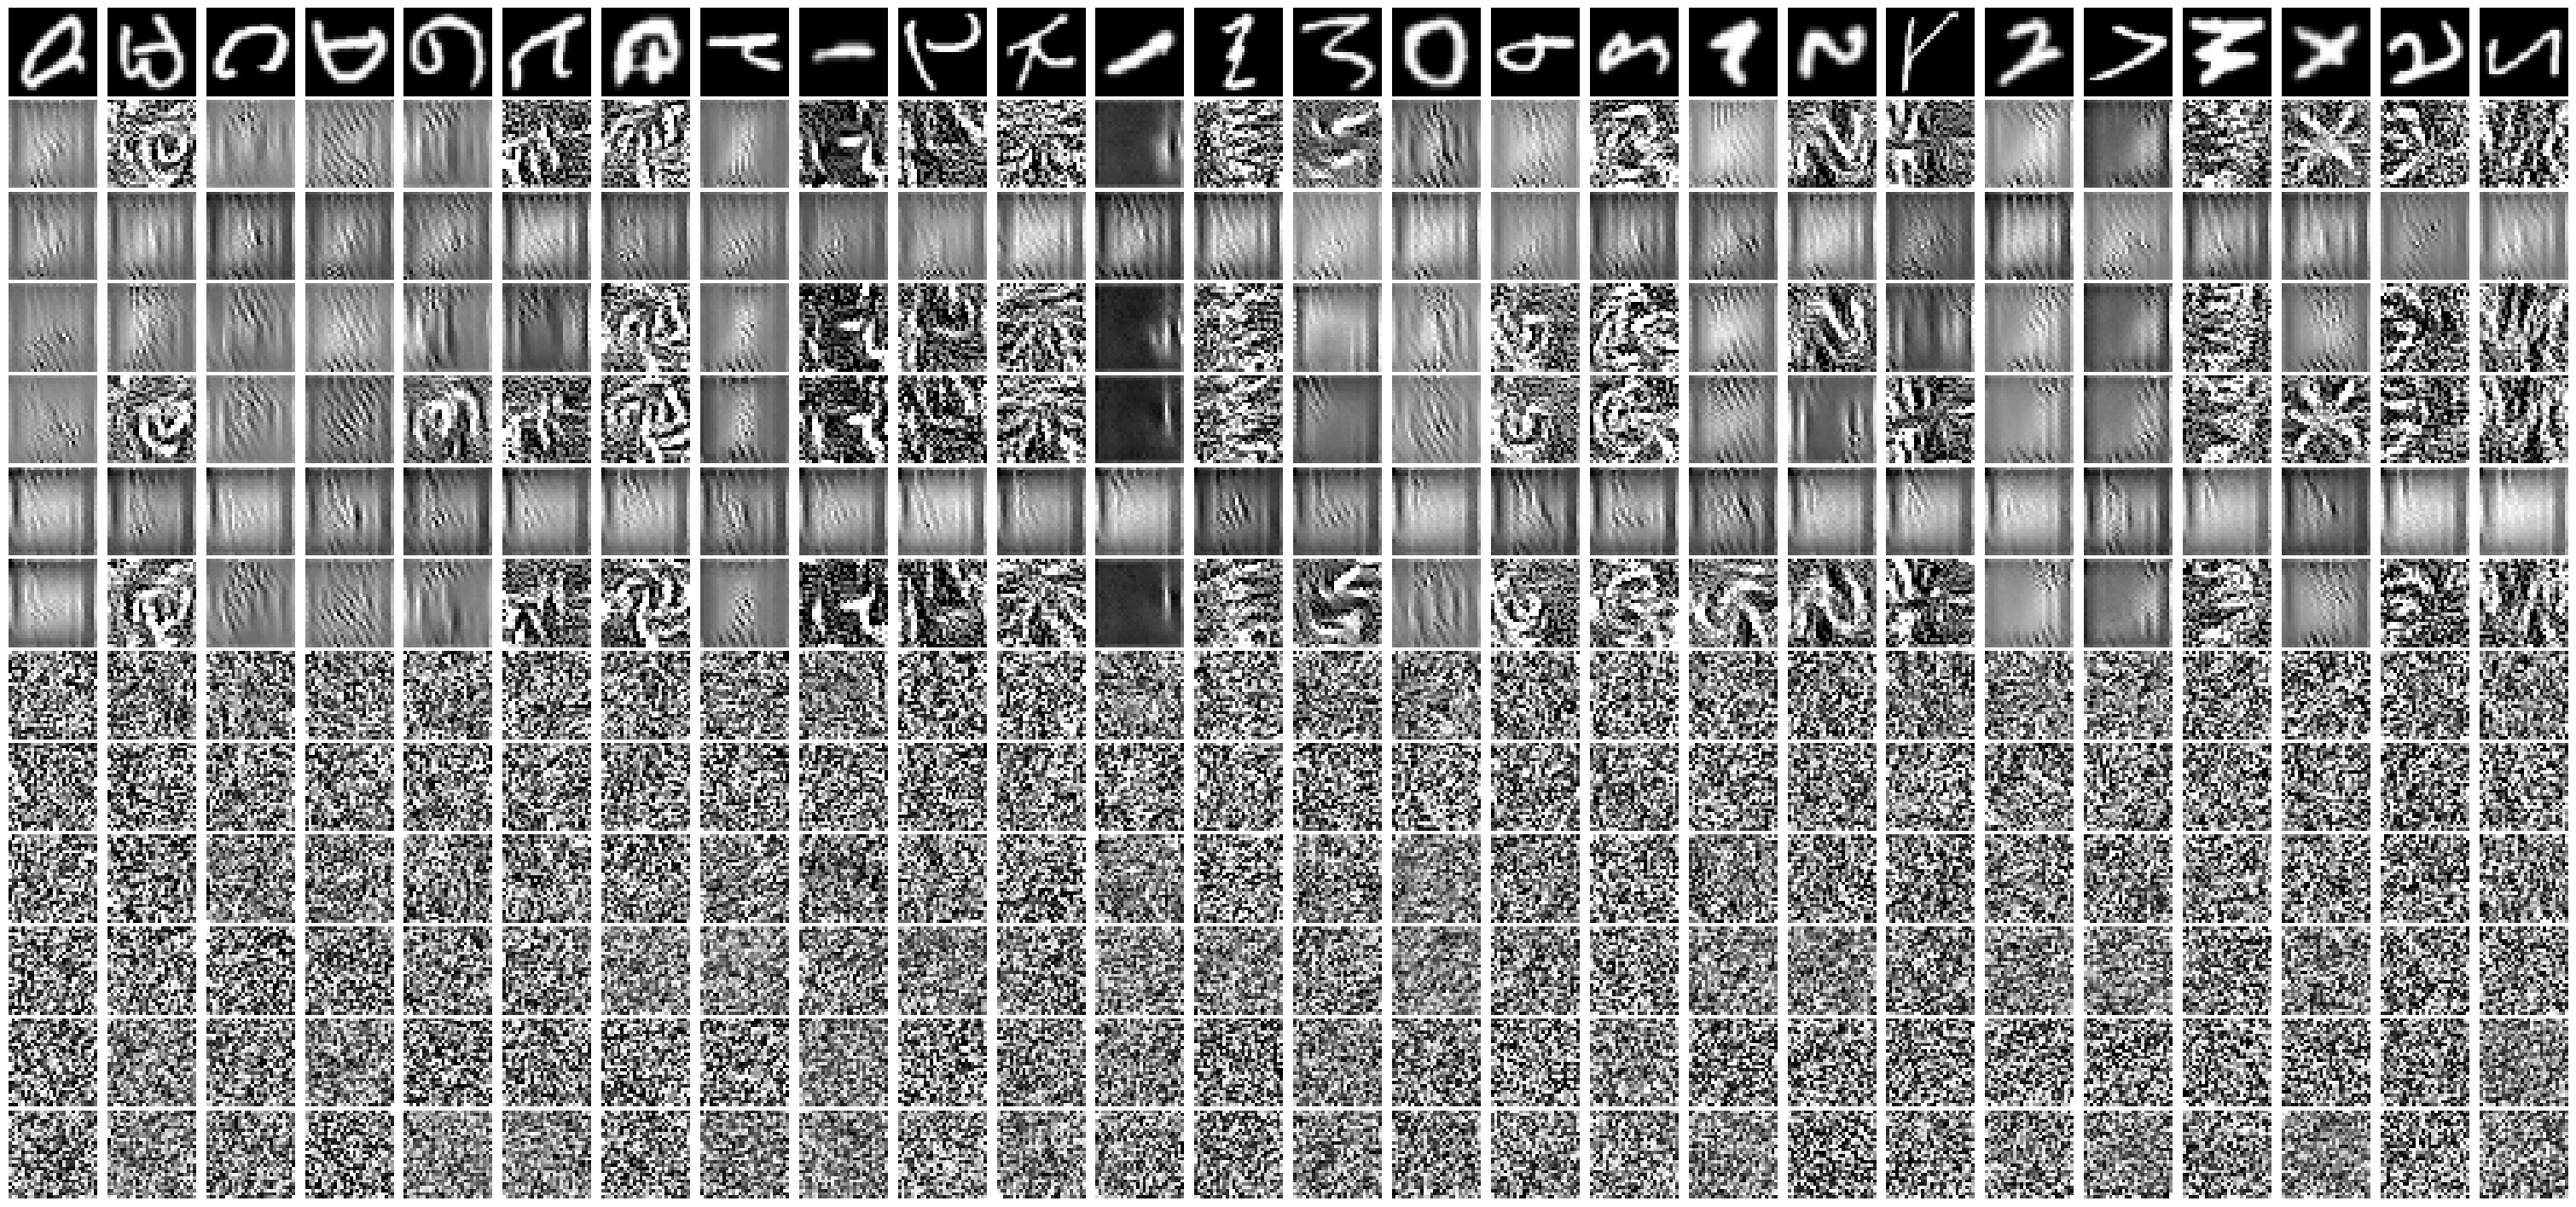

Saved: ./dlg_emnist_letters_4models/emnist_letters_all_attacks.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

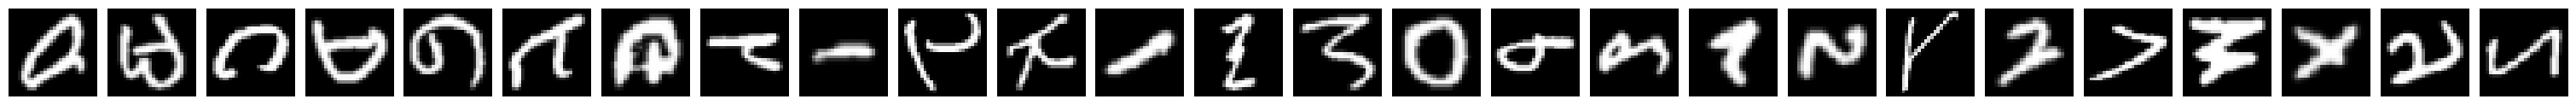

Saved: ./dlg_emnist_letters_4models/emnist_letters_original.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

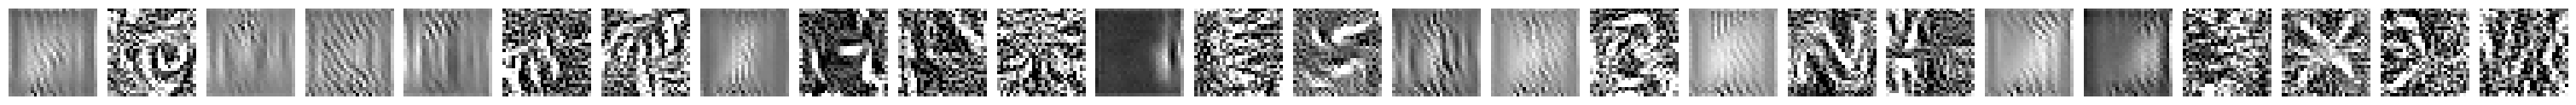

Saved: ./dlg_emnist_letters_4models/emnist_letters_baseline_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

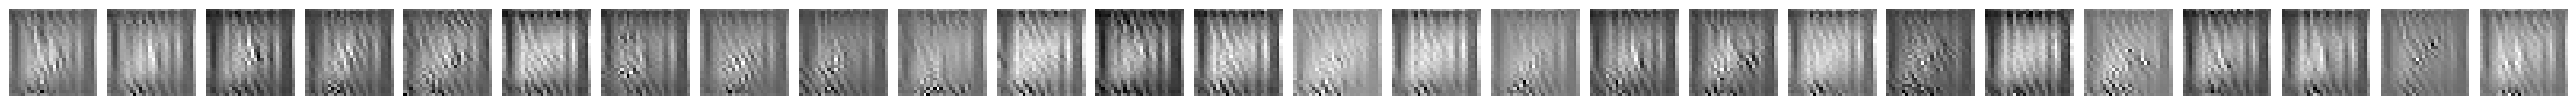

Saved: ./dlg_emnist_letters_4models/emnist_letters_baseline_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

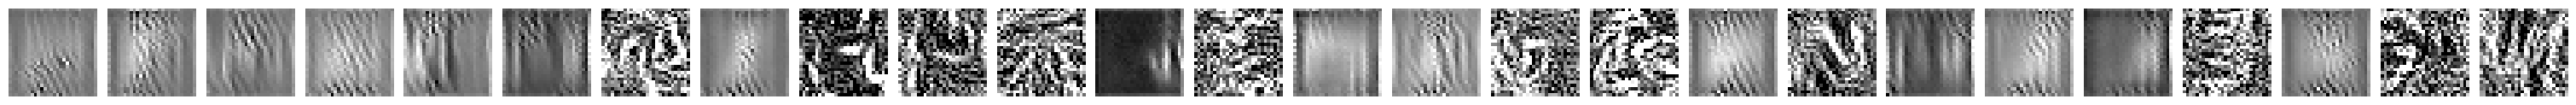

Saved: ./dlg_emnist_letters_4models/emnist_letters_baseline_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

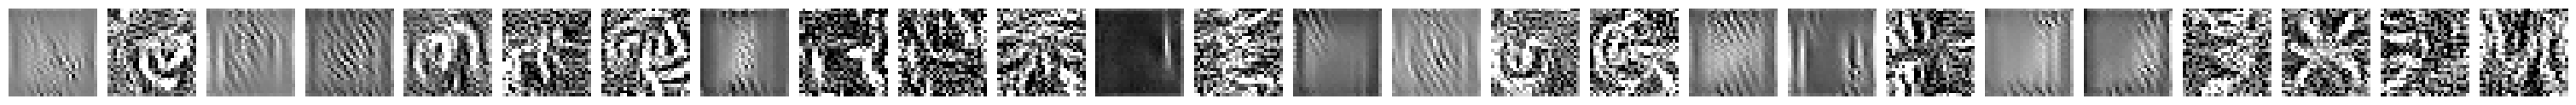

Saved: ./dlg_emnist_letters_4models/emnist_letters_fpman0_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

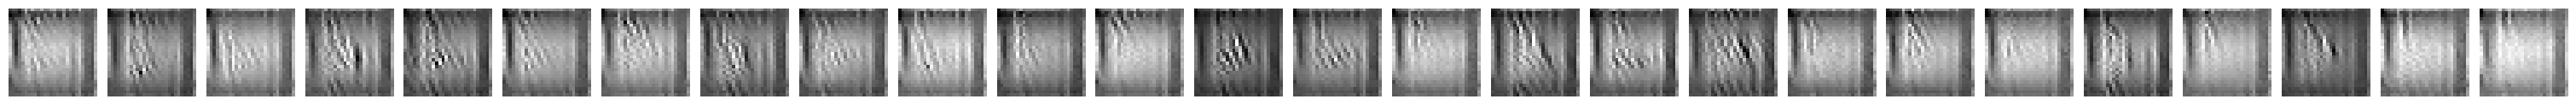

Saved: ./dlg_emnist_letters_4models/emnist_letters_fpman0_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

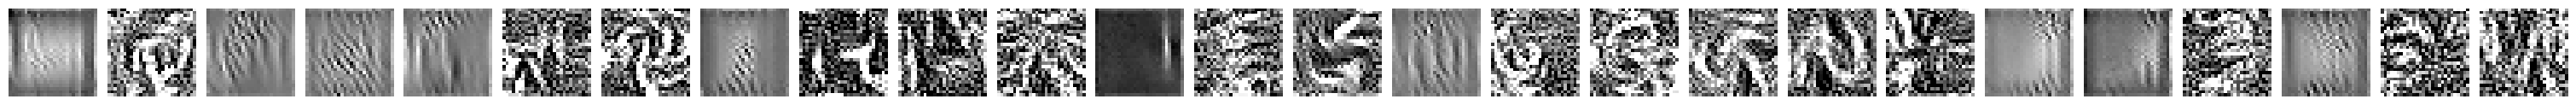

Saved: ./dlg_emnist_letters_4models/emnist_letters_fpman0_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

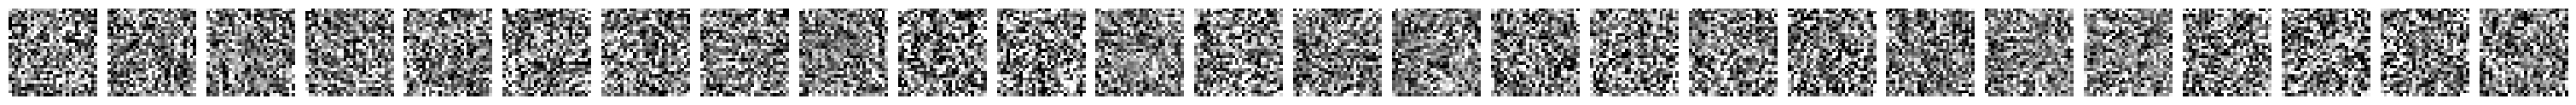

Saved: ./dlg_emnist_letters_4models/emnist_letters_fpman1_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

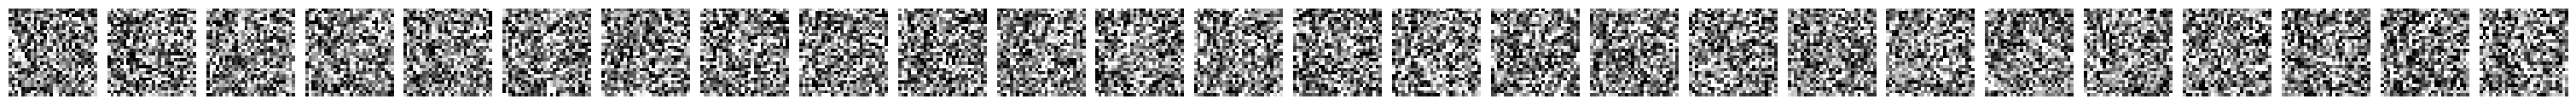

Saved: ./dlg_emnist_letters_4models/emnist_letters_fpman1_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

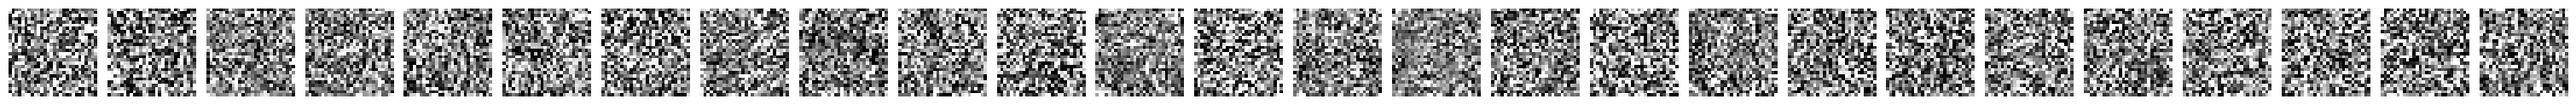

Saved: ./dlg_emnist_letters_4models/emnist_letters_fpman1_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

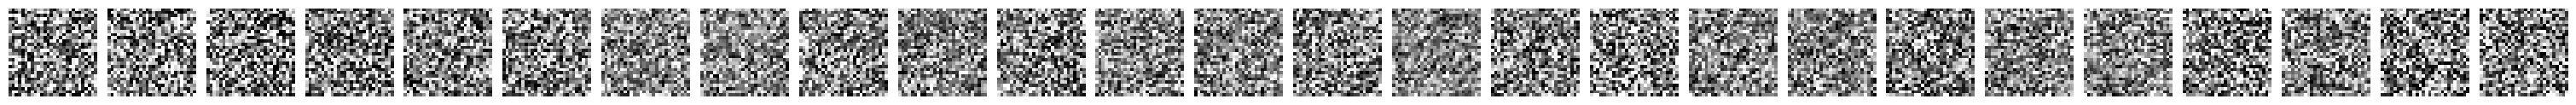

Saved: ./dlg_emnist_letters_4models/emnist_letters_fpman2_dlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

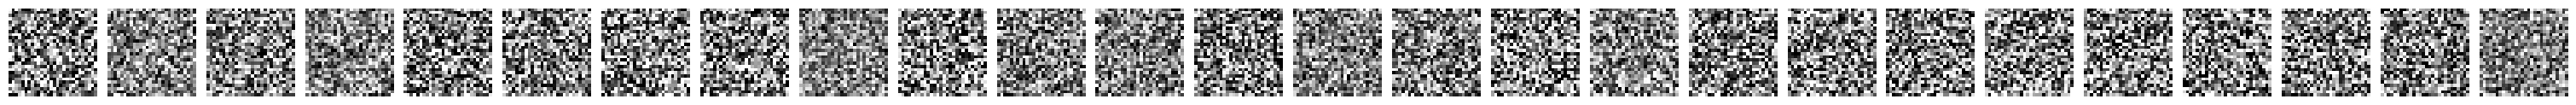

Saved: ./dlg_emnist_letters_4models/emnist_letters_fpman2_idlg.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

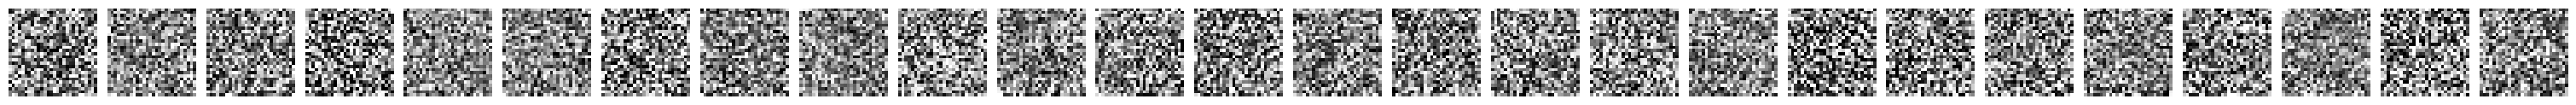

Saved: ./dlg_emnist_letters_4models/emnist_letters_fpman2_gradinv.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import matplotlib.pyplot as plt
from google.colab import files

SAVE_DIR = "./dlg_emnist_letters_4models"
os.makedirs(SAVE_DIR, exist_ok=True)

# -------------------------
# Data
# -------------------------
all_rows = [
    original,

    results["baseline"]["dlg"],
    results["baseline"]["idlg"],
    results["baseline"]["gi"],

    results["fpman0"]["dlg"],
    results["fpman0"]["idlg"],
    results["fpman0"]["gi"],

    results["fpman1"]["dlg"],
    results["fpman1"]["idlg"],
    results["fpman1"]["gi"],

    results["fpman2"]["dlg"],
    results["fpman2"]["idlg"],
    results["fpman2"]["gi"],
]

# =========================================================
# 1) FULL GRID (NO TOP/BOTTOM SPACE)
# =========================================================
fig, axes = plt.subplots(13, 26, figsize=(30, 14))

for r in range(13):
    for c in range(26):
        axes[r, c].imshow(all_rows[r][c], cmap="gray")
        axes[r, c].axis("off")

plt.subplots_adjust(
    wspace=0.12,
    hspace=0,          # ❌ no vertical gap
    left=0,
    right=1,
    top=1,
    bottom=0
)

full_path = os.path.join(SAVE_DIR, "emnist_letters_all_attacks.png")

plt.savefig(
    full_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0       # ❌ removes extra top/bottom margin
)

plt.show()

print("Saved:", full_path)
files.download(full_path)

# =========================================================
# 2) 13 SEPARATE ROW IMAGES (NO TOP/BOTTOM SPACE)
# =========================================================
row_names = [
    "emnist_letters_original",
    "emnist_letters_baseline_dlg",
    "emnist_letters_baseline_idlg",
    "emnist_letters_baseline_gradinv",
    "emnist_letters_fpman0_dlg",
    "emnist_letters_fpman0_idlg",
    "emnist_letters_fpman0_gradinv",
    "emnist_letters_fpman1_dlg",
    "emnist_letters_fpman1_idlg",
    "emnist_letters_fpman1_gradinv",
    "emnist_letters_fpman2_dlg",
    "emnist_letters_fpman2_idlg",
    "emnist_letters_fpman2_gradinv"
]

for i, row in enumerate(all_rows):

    fig, axes = plt.subplots(1, 26, figsize=(30, 2.5))

    for c in range(26):
        axes[c].imshow(row[c], cmap="gray")
        axes[c].axis("off")

    plt.subplots_adjust(
        wspace=0.12,
        hspace=0,
        left=0,
        right=1,
        top=1,
        bottom=0
    )

    path = os.path.join(SAVE_DIR, f"{row_names[i]}.png")

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight",
        pad_inches=0
    )

    plt.show()

    print("Saved:", path)
    files.download(path)